# Step 2: Team baseline models

Compares the team baselines (NB, LR, SVM, LightGBM, XGBoost, EBM) on the same test rows from their saved predictions. Details: `docs/steps/02_baseline_models.md`.

In [1]:
# Imports and paths
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
import nbutils as U
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
print("model prediction groups found:", len(list(U.PRED_DIR.glob("*/sarc_random__test.parquet"))))

model prediction groups found: 22


In [2]:
# Baseline metrics on sarc_random
BASE = [m for m, v in U.MODELS.items() if v[2] == "02 baselines"]
test, val = U.predictions("sarc_random")
lb = U.evaluate(test, val, BASE)
U.show(lb[["label", "family", "roc_auc", "pr_auc", "accuracy", "precision", "recall", "f1", "p75_recall"]])

,label,family,roc_auc,pr_auc,accuracy,precision,recall,f1,p75_recall
0,"LightGBM, + surface (baseline)",GBDT,0.8074,0.8224,0.7322,0.7559,0.7023,0.7281,0.7035
1,"XGBoost, + surface",GBDT,0.8061,0.8215,0.7308,0.7590,0.6929,0.7244,0.7011
2,"Logistic regression, + surface",Linear,0.8029,0.8159,0.7283,0.7484,0.7051,0.7261,0.6940
3,"Linear SVM, TF-IDF + lexicon + surface",Linear,0.8026,0.8153,0.7291,0.7532,0.6983,0.7247,0.6955
4,"LightGBM, word TF-IDF",GBDT,0.7964,0.8113,0.7217,0.7445,0.6929,0.7178,0.6750
5,"XGBoost, word TF-IDF",GBDT,0.7950,0.8096,0.7212,0.7510,0.6793,0.7133,0.6750
6,"Logistic regression, word TF-IDF",Linear,0.7941,0.8047,0.7206,0.7395,0.6991,0.7187,0.6716
7,"Multinomial NB, word TF-IDF",Naive Bayes,0.7798,0.7934,0.7041,0.7133,0.7035,0.7083,0.6255
8,"Complement NB, word TF-IDF",Naive Bayes,0.7798,0.7934,0.7044,0.7204,0.6884,0.7040,0.6255
9,"Team EBM (200k rows, 340 features)",Glass-box,0.7620,0.7812,0.6915,0.7231,0.6416,0.6799,0.5798


## 2.1 Stress test: unseen communities (`sarc_subreddit`)
Models are refitted on the `sarc_subreddit` training set with hyper-parameters frozen from `sarc_random`.

In [3]:
# Baselines on sarc_subreddit
ts, vs = U.predictions("sarc_subreddit")
lbs = U.evaluate(ts, vs, BASE)
cmp = lb[["model", "label", "roc_auc"]].merge(lbs[["model", "roc_auc"]], on="model", how="left", suffixes=("_random", "_subreddit"))
U.show(cmp)

,model,label,roc_auc_random,roc_auc_subreddit
0,lgbm_reply_tfidf_surface,"LightGBM, + surface (baseline)",0.8074,0.8023
1,xgb_reply_tfidf_surface,"XGBoost, + surface",0.8061,0.8014
2,lr_reply_tfidf_surface,"Logistic regression, + surface",0.8029,0.7963
3,svm_tfidf_lex_surface,"Linear SVM, TF-IDF + lexicon + surface",0.8026,0.7958
4,lgbm_reply_tfidf,"LightGBM, word TF-IDF",0.7964,0.7927
5,xgb_reply_tfidf,"XGBoost, word TF-IDF",0.7950,0.7910
6,lr_reply_tfidf,"Logistic regression, word TF-IDF",0.7941,0.7881
7,mnb_reply_tfidf,"Multinomial NB, word TF-IDF",0.7798,0.7716
8,cnb_reply_tfidf,"Complement NB, word TF-IDF",0.7798,0.7716
9,ebm_named340,"Team EBM (200k rows, 340 features)",0.7620,NaN


## 2.2 ROC curves (sarc_random test)

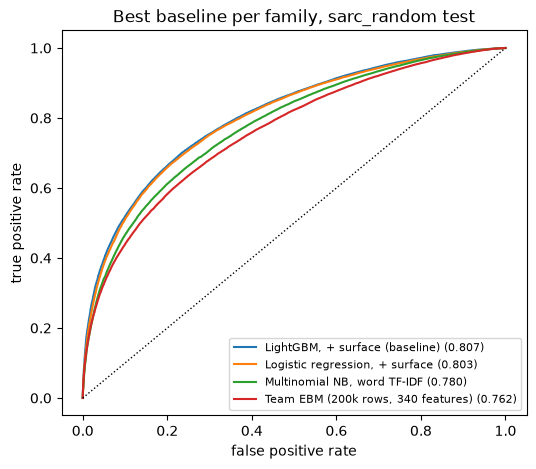

In [4]:
# ROC curves
from sklearn.metrics import roc_curve
fig, ax = plt.subplots(figsize=(6, 5))
best = lb.groupby("family").head(1)
for _, r in best.iterrows():
    fpr, tpr, _ = roc_curve(test["label"], test[r["model"]])
    ax.plot(fpr, tpr, label=f"{r['label']} ({r['roc_auc']:.3f})")
ax.plot([0, 1], [0, 1], "k:", lw=1); ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
ax.set_title("Best baseline per family, sarc_random test"); ax.legend(fontsize=8)
U.savefig(fig, "S02_baseline_roc.png"); plt.show()

## 2.3 Paired bootstrap against the LightGBM baseline
Every later step reports Δ AUC against `lgbm_reply_tfidf_surface` with a 95% paired-bootstrap interval on the same test rows.

In [5]:
# Paired bootstrap vs LightGBM
U.show(U.bootstrap_vs(test, BASE).merge(lb[["model", "label"]], on="model")[["label", "d_auc", "ci_low", "ci_high"]])

,label,d_auc,ci_low,ci_high
0,"Multinomial NB, word TF-IDF",-0.0277,-0.0295,-0.0258
1,"Multinomial NB, + surface",-0.0669,-0.0688,-0.0646
2,"Complement NB, word TF-IDF",-0.0277,-0.0295,-0.0258
3,"Complement NB, + surface",-0.0669,-0.0688,-0.0646
4,"Logistic regression, word TF-IDF",-0.0134,-0.0149,-0.0119
5,"Logistic regression, + surface",-0.0045,-0.0056,-0.0035
6,"Linear SVM, TF-IDF + lexicon + surface",-0.0049,-0.0061,-0.0036
7,"LightGBM, word TF-IDF",-0.0110,-0.0119,-0.0100
8,"XGBoost, word TF-IDF",-0.0124,-0.0133,-0.0114
9,"XGBoost, + surface",-0.0013,-0.0019,-0.0007


In [6]:
# Save table
lb.assign(set="sarc_random").to_csv(U.RESULTS / "step02_baselines.csv", index=False)

## 2.4 Other team baselines
Tree-based (`modelling/tree-based/`) and SGD (`modelling/Margin-Based/`) results from their saved test leaderboards.

In [7]:
# Saved leaderboards of tree-based and margin-based notebooks
other = pd.concat([pd.read_csv(U.OFFICIAL / f"results/{d}/test_leaderboard.csv").assign(source=d) for d in ["tree-based", "margin-based"]])
other[other["operating point"].str.startswith("default")][["source", "model", "roc_auc", "precision", "recall", "f1"]].reset_index(drop=True)

,source,model,roc_auc,precision,recall,f1
0,tree-based,Decision Tree,0.6894,0.7106,0.5034,0.5893
1,tree-based,Random Forest,0.7603,0.7214,0.6408,0.6787
2,tree-based,Gradient Boosting,0.7759,0.7335,0.6558,0.6925
3,margin-based,Linear SVM,0.8026,0.7532,0.6982,0.7246
4,margin-based,SGD (hinge),0.7860,0.7514,0.6631,0.7045


## 2.5 Takeaways

- **LightGBM on reply TF-IDF + 17 surface features (0.8074)** is the strongest baseline and the reference for every later Δ.
- Logistic regression and the linear SVM are within 0.005 of it; the bottleneck is the representation, not the classifier.
- Surface features help every family except Naive Bayes (their dense scale breaks the multinomial assumption).
- The team EBM (0.762) is the most readable model but is trained on a 200k sample and uses a subreddit encoding.
- Single decision trees, random forests and histogram gradient boosting on the tree-based feature set stay below 0.78; SGD (hinge) reaches 0.786.
